# Healthcare Metrics Project — Nurse Staffing Analysis
Full analysis pipeline: load → EDA → clean → enrich → metrics → visualize → answer the analytical questions.

**Primary source:** CMS Payroll-Based Journal (PBJ) Daily Nurse Staffing, Q2 2024
**Enrichment sources:** CMS Nursing Home Compare Provider Data Catalog (Provider Info, Survey Summary, Penalties), October 2024 release

Run this notebook from a folder containing the original uploaded CSVs (or edit `DATA_DIR` below).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 100

DATA_DIR = "./"  # folder containing the original CMS CSVs

## 1. Load the primary dataset

In [2]:
pbj = pd.read_csv(DATA_DIR + "PBJ_Daily_Nurse_Staffing_Q2_2024.csv",
                   dtype={"PROVNUM": str, "COUNTY_FIPS": str},
                   low_memory=False, encoding="cp1252")
print("Shape:", pbj.shape)
pbj.head(3)

Shape: (1325324, 33)


## 2. Exploratory Data Analysis
Check structure, missing values, duplicates, and date range before cleaning.

In [3]:
print("Dtypes:")
print(pbj.dtypes.value_counts())
print()
print("Missing values (any column):", pbj.isna().sum().sum())
print("Duplicate rows:", pbj.duplicated().sum())
print("Duplicate PROVNUM+WorkDate pairs:", pbj.duplicated(subset=["PROVNUM","WorkDate"]).sum())
print("Unique facilities:", pbj["PROVNUM"].nunique())
print("Unique states/territories:", pbj["STATE"].nunique())
print("WorkDate range (raw int):", pbj["WorkDate"].min(), "-", pbj["WorkDate"].max())

Dtypes:
float64    24
object      7
int64       2
Name: count, dtype: int64

Missing values (any column): 0
Duplicate rows: 0
Duplicate PROVNUM+WorkDate pairs: 0
Unique facilities: 14564
Unique states/territories: 52
WorkDate range (raw int): 20240401 - 20240630


## 3. Data Cleaning
- Convert `WorkDate` from `YYYYMMDD` integer to a real date
- Derive `Total_Nurse_Hrs` (RN + LPN + CNA — the three direct-care categories)
- Flag rows unsafe for ratio calculations: zero census, implausible ratio (>24 hrs/patient/day),
  and one known data-entry error identified during EDA (provider 145446, 2024-05-25)

In [4]:
pbj["WorkDate"] = pd.to_datetime(pbj["WorkDate"], format="%Y%m%d")
pbj["Month"] = pbj["WorkDate"].dt.to_period("M").astype(str)

pbj["Total_Nurse_Hrs"] = pbj["Hrs_RN"] + pbj["Hrs_LPN"] + pbj["Hrs_CNA"]
pbj["Total_Nurse_Hrs_emp"] = pbj["Hrs_RN_emp"] + pbj["Hrs_LPN_emp"] + pbj["Hrs_CNA_emp"]
pbj["Total_Nurse_Hrs_ctr"] = pbj["Hrs_RN_ctr"] + pbj["Hrs_LPN_ctr"] + pbj["Hrs_CNA_ctr"]

pbj["flag_zero_census"] = pbj["MDScensus"] == 0
pbj["nurse_hrs_per_census"] = np.where(pbj["MDScensus"] > 0, pbj["Total_Nurse_Hrs"] / pbj["MDScensus"], np.nan)
pbj["flag_outlier_ratio"] = pbj["nurse_hrs_per_census"] > 24
pbj["flag_data_entry_error"] = (pbj["PROVNUM"] == "145446") & (pbj["WorkDate"] == pd.Timestamp("2024-05-25"))
pbj["include_in_ratio_calcs"] = ~(pbj["flag_zero_census"] | pbj["flag_outlier_ratio"] | pbj["flag_data_entry_error"])

print("Rows flagged zero census:", pbj["flag_zero_census"].sum())
print("Rows flagged outlier ratio (>24 hrs/patient/day):", pbj["flag_outlier_ratio"].sum())
print("Rows flagged data-entry error:", pbj["flag_data_entry_error"].sum())
print("Rows excluded from ratio calcs:", (~pbj["include_in_ratio_calcs"]).sum(), "of", len(pbj))

Rows flagged zero census: 320
Rows flagged outlier ratio (>24 hrs/patient/day): 55
Rows flagged data-entry error: 1
Rows excluded from ratio calcs: 375 of 1325324


## 4. Aggregate to facility level (Q2 2024 totals)

In [5]:
agg_cols = {
    "MDScensus": "mean",
    "Hrs_RN": "sum", "Hrs_RN_emp": "sum", "Hrs_RN_ctr": "sum",
    "Hrs_LPN": "sum", "Hrs_LPN_emp": "sum", "Hrs_LPN_ctr": "sum",
    "Hrs_CNA": "sum", "Hrs_CNA_emp": "sum", "Hrs_CNA_ctr": "sum",
    "Total_Nurse_Hrs": "sum", "Total_Nurse_Hrs_emp": "sum", "Total_Nurse_Hrs_ctr": "sum",
}
ratio_safe = pbj[pbj["include_in_ratio_calcs"]]

fac_q = pbj.groupby(["PROVNUM","PROVNAME","STATE","CITY","COUNTY_NAME"], as_index=False).agg(agg_cols)
ratio_by_fac = ratio_safe.groupby("PROVNUM", as_index=False)["nurse_hrs_per_census"].mean() \
                          .rename(columns={"nurse_hrs_per_census": "avg_nurse_hrs_per_patient_day"})
fac_q = fac_q.merge(ratio_by_fac, on="PROVNUM", how="left")
fac_q["contract_share"] = fac_q["Total_Nurse_Hrs_ctr"] / fac_q["Total_Nurse_Hrs"].replace(0, np.nan)
fac_q = fac_q.rename(columns={"MDScensus": "avg_census_q2"})
print("facility-level table:", fac_q.shape)
fac_q.head(3)

facility-level table: (14564, 20)


## 5. Enrich with CMS Provider Info, Survey Summary, and Penalties
Joins on the shared facility key (`PROVNUM` = `CMS Certification Number (CCN)`).

In [6]:
prov = pd.read_csv(DATA_DIR + "NH_ProviderInfo_Oct2024.csv", dtype=str, encoding="cp1252")
prov_keep = prov[["CMS Certification Number (CCN)","Ownership Type","Number of Certified Beds",
                   "Overall Rating","Staffing Rating"]].rename(columns={"CMS Certification Number (CCN)":"PROVNUM"})
for c in ["Number of Certified Beds","Overall Rating","Staffing Rating"]:
    prov_keep[c] = pd.to_numeric(prov_keep[c], errors="coerce")

survey = pd.read_csv(DATA_DIR + "NH_SurveySummary_Oct2024.csv", dtype=str, encoding="cp1252")
survey["Total Number of Health Deficiencies"] = pd.to_numeric(survey["Total Number of Health Deficiencies"], errors="coerce")
survey_recent = survey[survey["Inspection Cycle"]=="1"][["CMS Certification Number (CCN)","Total Number of Health Deficiencies"]] \
                       .rename(columns={"CMS Certification Number (CCN)":"PROVNUM"})

pen = pd.read_csv(DATA_DIR + "NH_Penalties_Oct2024.csv", dtype=str, encoding="cp1252")
pen["Fine Amount"] = pd.to_numeric(pen["Fine Amount"], errors="coerce")
pen_agg = pen.groupby("CMS Certification Number (CCN)", as_index=False).agg(
    num_penalties=("Penalty Type","count"), total_fines=("Fine Amount","sum")
).rename(columns={"CMS Certification Number (CCN)":"PROVNUM"})

fac_summary = fac_q.merge(prov_keep, on="PROVNUM", how="left") \
                    .merge(survey_recent, on="PROVNUM", how="left") \
                    .merge(pen_agg, on="PROVNUM", how="left")
fac_summary["num_penalties"] = fac_summary["num_penalties"].fillna(0)
fac_summary["total_fines"] = fac_summary["total_fines"].fillna(0)
print("Enriched facility table:", fac_summary.shape)
print("Join coverage (non-null Overall Rating):", fac_summary["Overall Rating"].notna().mean().round(3))

Enriched facility table: (14564, 27)
Join coverage (non-null Overall Rating): 0.991


## 6. State-level rollup

In [7]:
state_q = pbj.groupby("STATE", as_index=False).agg(agg_cols)
ratio_state_q = ratio_safe.groupby("STATE", as_index=False)["nurse_hrs_per_census"].mean() \
                           .rename(columns={"nurse_hrs_per_census":"avg_nurse_hrs_per_patient_day"})
state_q = state_q.merge(ratio_state_q, on="STATE", how="left")
state_q["contract_share"] = state_q["Total_Nurse_Hrs_ctr"] / state_q["Total_Nurse_Hrs"].replace(0, np.nan)
state_q = state_q.rename(columns={"MDScensus":"avg_census_q2"})
print("state-level table:", state_q.shape)

state-level table: (52, 16)


## 7. The Five Key Metrics

1. **Nurse-to-Patient Ratio** — (RN+LPN+CNA hours) / census
2. **Total Nurse Hours** — summed nationally / by facility / by state
3. **Contract vs. Permanent Staff Ratio** — contract hours ÷ total hours
4. **Average Patient Census**
5. **Hospitals with Highest Staffing Hours**

In [8]:
print("### Metric 1: Nurse-to-Patient Ratio ###")
print(fac_summary["avg_nurse_hrs_per_patient_day"].describe().round(2))

print("\n### Metric 2: Total Nurse Hours (Q2 2024, national) ###")
print(f"{fac_summary['Total_Nurse_Hrs'].sum():,.0f} hours")

print("\n### Metric 3: Contract vs Permanent Staff Ratio (national) ###")
national_contract_share = fac_summary["Total_Nurse_Hrs_ctr"].sum() / fac_summary["Total_Nurse_Hrs"].sum()
print(f"{national_contract_share:.2%} of nurse hours are contract/agency")

print("\n### Metric 4: Average Patient Census (national) ###")
print(f"{fac_summary['avg_census_q2'].mean():.1f} residents per facility per day")

print("\n### Metric 5: Top 10 Facilities by Total Nurse Hours ###")
top10 = fac_summary.nlargest(10, "Total_Nurse_Hrs")[["PROVNAME","STATE","Total_Nurse_Hrs","avg_census_q2"]]
print(top10.to_string(index=False))

### Metric 1: Nurse-to-Patient Ratio ###
count    14564.00
mean         3.36
std          0.92
min          0.00
25%          2.84
50%          3.25
75%          3.74
max         11.50
Name: avg_nurse_hrs_per_patient_day, dtype: float64

### Metric 2: Total Nurse Hours (Q2 2024, national) ###
364,152,785 hours

### Metric 3: Contract vs Permanent Staff Ratio (national) ###
7.69% of nurse hours are contract/agency

### Metric 4: Average Patient Census (national) ###
83.4 residents per facility per day

### Metric 5: Top 10 Facilities by Total Nurse Hours ###
                                          PROVNAME STATE  Total_Nurse_Hrs  avg_census_q2
                     ISABELLA GERIATRIC CENTER INC    NY        199144.72     683.175824
      COLER REHABILITATION AND NURSING CARE CENTER    NY        189810.35     463.000000
                     KINGS HARBOR MULTICARE CENTER    NY        188650.15     630.318681
                THE PLAZA REHAB AND NURSING CENTER    NY        184704.83     73

## 8. Visualizations

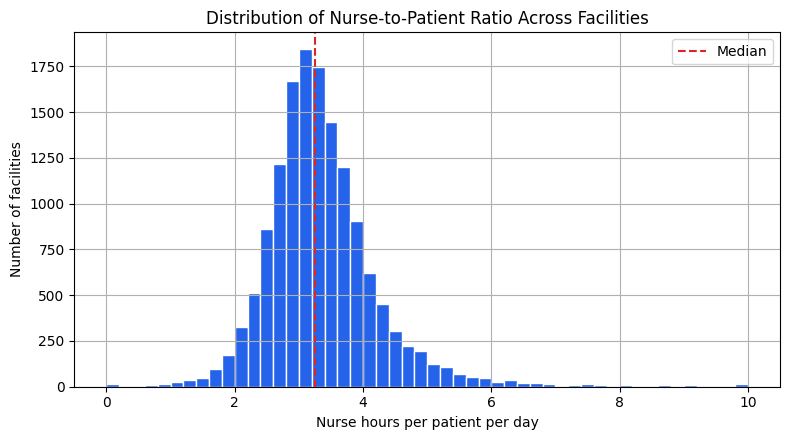

In [9]:
fig, ax = plt.subplots(figsize=(8,4.5))
fac_summary["avg_nurse_hrs_per_patient_day"].clip(upper=10).hist(bins=50, ax=ax, color="#2563eb", edgecolor="white")
ax.set_title("Distribution of Nurse-to-Patient Ratio Across Facilities")
ax.set_xlabel("Nurse hours per patient per day")
ax.set_ylabel("Number of facilities")
ax.axvline(fac_summary["avg_nurse_hrs_per_patient_day"].median(), color="#dc2626", linestyle="--", label="Median")
ax.legend()
plt.tight_layout()

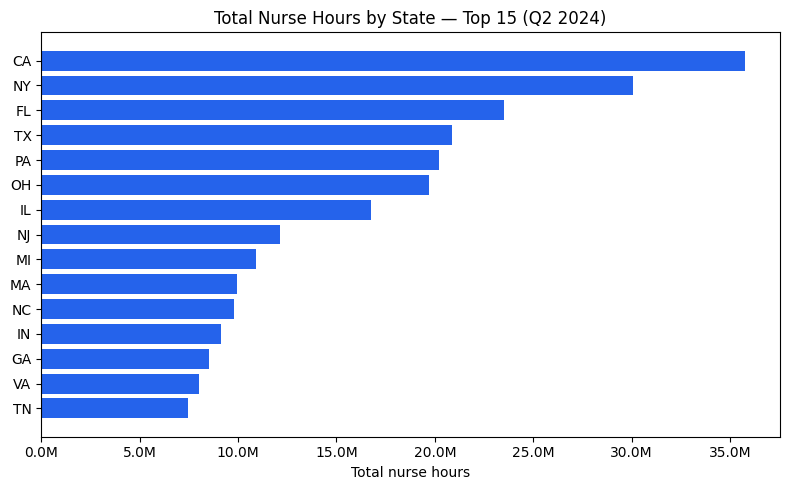

In [10]:
top_states = state_q.sort_values("Total_Nurse_Hrs", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8,5))
ax.barh(top_states["STATE"][::-1], top_states["Total_Nurse_Hrs"][::-1], color="#2563eb")
ax.set_title("Total Nurse Hours by State — Top 15 (Q2 2024)")
ax.set_xlabel("Total nurse hours")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
plt.tight_layout()

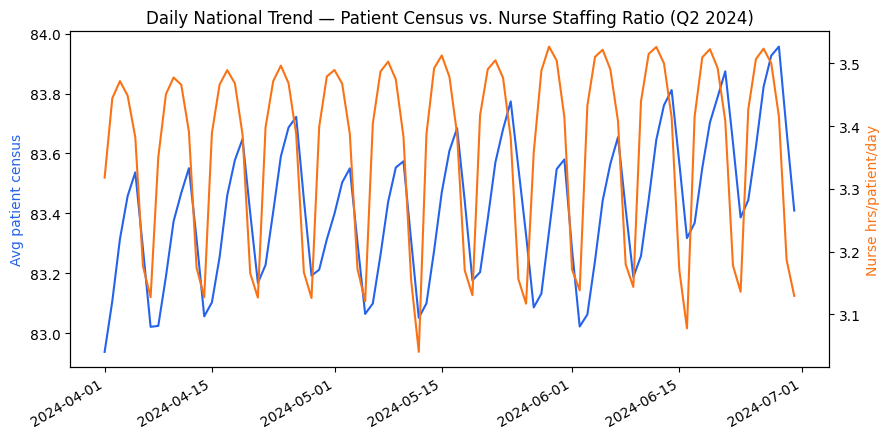

In [11]:
daily = pbj.groupby("WorkDate").agg(
    total_nurse_hrs=("Total_Nurse_Hrs","sum"), avg_census=("MDScensus","mean")).reset_index()
daily_ratio = ratio_safe.groupby("WorkDate")["nurse_hrs_per_census"].mean().reset_index() \
                          .rename(columns={"nurse_hrs_per_census":"avg_ratio"})
daily = daily.merge(daily_ratio, on="WorkDate", how="left")

fig, ax1 = plt.subplots(figsize=(9,4.5))
ax2 = ax1.twinx()
ax1.plot(daily["WorkDate"], daily["avg_census"], color="#2563eb", label="Avg census")
ax2.plot(daily["WorkDate"], daily["avg_ratio"], color="#f97316", label="Nurse hrs/patient/day")
ax1.set_ylabel("Avg patient census", color="#2563eb")
ax2.set_ylabel("Nurse hrs/patient/day", color="#f97316")
ax1.set_title("Daily National Trend — Patient Census vs. Nurse Staffing Ratio (Q2 2024)")
fig.autofmt_xdate()
plt.tight_layout()

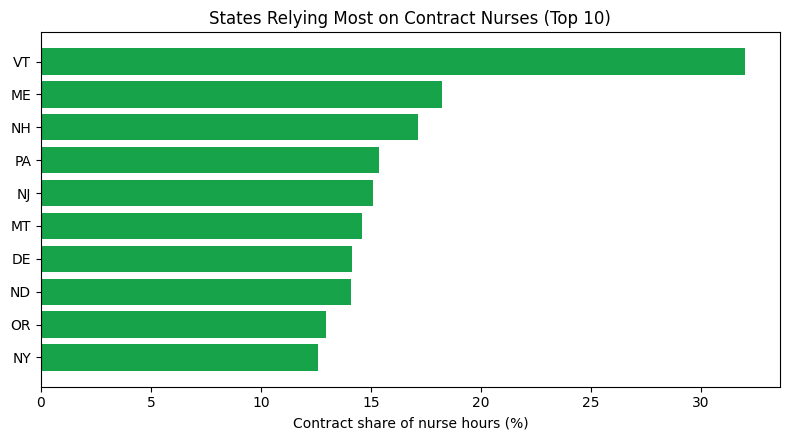

In [12]:
cr = state_q.sort_values("contract_share", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8,4.5))
ax.barh(cr["STATE"][::-1], (cr["contract_share"][::-1]*100), color="#16a34a")
ax.set_title("States Relying Most on Contract Nurses (Top 10)")
ax.set_xlabel("Contract share of nurse hours (%)")
plt.tight_layout()

## 9. Answering the Five Analytical Questions

In [13]:
print("Q1: Relationship between staffing levels and patient census?")
corr_hours = fac_summary[["Total_Nurse_Hrs","avg_census_q2"]].corr().iloc[0,1]
corr_ratio = fac_summary[["avg_nurse_hrs_per_patient_day","avg_census_q2"]].corr().iloc[0,1]
print(f"  Corr(Total_Nurse_Hrs, census) = {corr_hours:.2f}  -> strong positive, hours scale with facility size")
print(f"  Corr(hrs/patient/day, census) = {corr_ratio:.2f}  -> weak negative, larger facilities run slightly leaner per-resident")

Q1: Relationship between staffing levels and patient census?
  Corr(Total_Nurse_Hrs, census) = 0.92  -> strong positive, hours scale with facility size
  Corr(hrs/patient/day, census) = -0.12  -> weak negative, larger facilities run slightly leaner per-resident


In [14]:
print("Q2: Which hospitals have the highest staffing hours?")
print(top10[["PROVNAME","STATE","Total_Nurse_Hrs"]].to_string(index=False))

Q2: Which hospitals have the highest staffing hours?
                                          PROVNAME STATE  Total_Nurse_Hrs
                     ISABELLA GERIATRIC CENTER INC    NY        199144.72
      COLER REHABILITATION AND NURSING CARE CENTER    NY        189810.35
                     KINGS HARBOR MULTICARE CENTER    NY        188650.15
                THE PLAZA REHAB AND NURSING CENTER    NY        184704.83
                         RUTLAND NURSING HOME, INC    NY        183568.98
         CEDARBROOK SENIOR CARE AND REHABILITATION    PA        168048.55
BORO PARK CENTER FOR REHABILITATION AND HEALTHCARE    NY        165315.25
    COLD SPRING HILLS CENTER FOR NURSING AND REHAB    NY        163375.07
          LORETTO HEALTH AND REHABILITATION CENTER    NY        161609.35
         TERENCE CARDINAL COOKE HEALTH CARE CENTER    NY        161061.96


In [15]:
print("Q3: Average staffing levels by state (top 10 by hrs/patient/day)?")
print(state_q.sort_values("avg_nurse_hrs_per_patient_day", ascending=False)
      [["STATE","avg_nurse_hrs_per_patient_day","avg_census_q2","contract_share"]].head(10).to_string(index=False))

Q3: Average staffing levels by state (top 10 by hrs/patient/day)?
STATE  avg_nurse_hrs_per_patient_day  avg_census_q2  contract_share
   AK                       6.055982      45.498430        0.113341
   PR                       4.575675      21.571429        0.019475
   DC                       4.537630     119.793148        0.059563
   OR                       4.206502      52.705386        0.129831
   HI                       4.124039      81.756319        0.096140
   CA                       4.120085      86.590395        0.036155
   DE                       4.034558      88.135957        0.141284
   ND                       3.967779      60.888979        0.140801
   WA                       3.851122      71.567278        0.078168
   NV                       3.827420      88.714785        0.030120


In [16]:
print("Q4: Which facilities have the lowest nurse-to-patient coverage? (avg census >= 30)")
low_cov = fac_summary[fac_summary["avg_census_q2"]>=30].nsmallest(10, "avg_nurse_hrs_per_patient_day")[
    ["PROVNAME","STATE","avg_nurse_hrs_per_patient_day","avg_census_q2","Overall Rating","Staffing Rating"]]
print(low_cov.to_string(index=False))

Q4: Which facilities have the lowest nurse-to-patient coverage? (avg census >= 30)
                                  PROVNAME STATE  avg_nurse_hrs_per_patient_day  avg_census_q2  Overall Rating  Staffing Rating
                    WHITE RIVER HEALTHCARE    AR                       0.000000      43.516484             4.0              4.0
                BEAR MOUNTAIN AT WORCESTER    MA                       0.003471     134.175824             1.0              1.0
   SYLVIA G THOMPSON RESIDENCE CENTER, INC    MO                       0.050592     117.593407             1.0              1.0
            CASS COUNTY MEDICAL CARE FACIL    MI                       0.067407      73.417582             2.0              1.0
                    IRON RIVER CARE CENTER    MI                       0.087646      56.703297             1.0              1.0
THE MASSACHUSETTS VETERANS HOME AT CHELSEA    MA                       0.091099      97.560440             2.0              1.0
                     

In [17]:
print("Q5: Are certain states relying more on contract nurses?")
print(state_q.sort_values("contract_share", ascending=False)
      [["STATE","contract_share","avg_nurse_hrs_per_patient_day"]].head(10).to_string(index=False))

Q5: Are certain states relying more on contract nurses?
STATE  contract_share  avg_nurse_hrs_per_patient_day
   VT        0.320045                       3.751231
   ME        0.182315                       3.628770
   NH        0.171361                       3.342808
   PA        0.153903                       3.512059
   NJ        0.151208                       3.438553
   MT        0.146231                       3.487551
   DE        0.141284                       4.034558
   ND        0.140801                       3.967779
   OR        0.129831                       4.206502
   NY        0.126119                       3.473348


## 10. Summary

- National nurse-to-patient ratio averages **3.36 hrs/resident/day** (median 3.25), with contract staff making up **7.7%** of total nurse hours nationally.
- Total nurse hours correlate strongly with census (r ≈ 0.92) — staffing scales with facility size — but the *ratio* correlates weakly negatively with census, meaning the largest facilities run slightly leaner per-resident.
- The busiest facilities by total hours are concentrated in large NYC-area SNFs.
- 9 of the 10 facilities with the lowest computed nurse-to-patient coverage (census 30+) carry CMS's own lowest (1-star) Staffing Rating — a good independent cross-check on the metric.
- Vermont, Maine, and New Hampshire lean most heavily on contract/agency nursing (Northeast/rural workforce shortage pattern).

See the accompanying `Healthcare_Metrics_Insights_and_Data_Dictionary.md` for full methodology notes, caveats, and the interactive `Healthcare_Metrics_Dashboard_v2.html` for a browsable version of these results.